## Preliminaries

Freeze backbone from ResNet trained in `ResNet_Train.ipynb` and transform concept images in the latent space of the CNN.

The explanation will then be formulated on the basis of the $k$ nearest concepts.

In [1]:
!pwd
import sys, os
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import time
import shutil
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-02-09 14:50:54.366830: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-02-09 14:50:54.920152: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
metafolder = './beexplainable/metafiles/Fungi/raw/'
CONCEPTS_PATH = '../data/DanishFungi/Concepts_3spec/'

CLASSES_PATH = metafolder + 'classes.txt'
FUNGI_PATH = '../data/DanishFungi/DF20M_3spec/'

IMAGES_PATH = metafolder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + 'image_class_labels.txt'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/concepts/'

## Load Images

In [5]:
batch_size = 64
img_height = img_width = 224

### Fungi Images

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids_bees = list( img_dict.keys() )
y_true_bees   = list( img_label_dict.values() )
y_true_bees   = np.asarray(y_true_bees, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
len(y_true_bees)

670

In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Russula_emetica', 'Russula_paludosa', 'Russula_rosea']

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_bees, list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH),
                                          label)

2024-02-09 14:50:54.985715: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
train_val_set = ps.parse_to_dataset(file_ids_bees, y_true_bees, parse_image_lab)
train_val_set = train_val_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_val_set = train_val_set.map(lambda x, y: (normalization_layer(x), y))

2024-02-09 14:50:58.909941: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


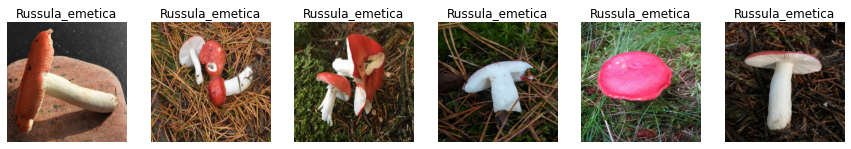

In [10]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in train_val_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(classes[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [11]:
for image_batch, labels_batch in train_val_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


2024-02-09 14:51:02.604511: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


### Concept Images

In [12]:
# Store concepts, image paths and create label vector from subfolder names
concepts, concept_files, y_true_con = [], [], []
concept_subfolders = sorted( glob.glob(CONCEPTS_PATH + '*') )
for i in range(len(concept_subfolders)):
    # Add concept from subfolder base name
    concept = os.path.basename(concept_subfolders[i])
    concepts.append( concept )

    # Get image paths in current concept subfolder
    c_files = glob.glob(CONCEPTS_PATH + concept + '/*.jpg')
    concept_files += [c[len(CONCEPTS_PATH):] for c in c_files] # remove the constant path to the common dir.
    y_true_con += [i] * len(c_files)

In [13]:
concepts

['bright_red', 'reddish_orange', 'rose_red']

In [14]:
# Define file ids (for consistency with the parsers in the pipeline)
# Note: the metafile readers return a Dict[str, str]
file_ids_con = [str(i) for i in range(1, len(y_true_con)+1)]

In [15]:
# Get dictionary of file IDs and file names
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_con, concept_files),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, CONCEPTS_PATH),
                                          label)

In [16]:
# Conversion to tf.Dataset
concept_set = ps.parse_to_dataset(file_ids_con, y_true_con, parse_image_lab)
concept_set = concept_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
concept_set = concept_set.map(lambda x, y: (normalization_layer(x), y))

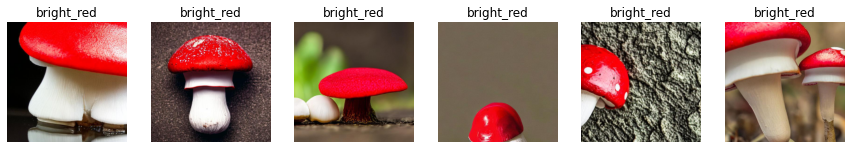

In [17]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in concept_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(concepts[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [18]:
for image_batch, labels_batch in concept_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=int32)


Mapping relevant concepts to true class labels

In [19]:
# One-hot-encode the concepts
enc = OneHotEncoder().fit([[0], [1], [2]])
concept_basis = enc.transform([[0], [1], [2]]).toarray()
# bright_red = 100 -> emetica
# orange_red = 010 -> paludosa
# rose_red   = 001 -> rosea
lookup_cls_concepts = [concept_basis[0],
                       concept_basis[1],
                       concept_basis[2]]
lookup_cls_concepts[2]

array([0., 0., 1.])

## Model Loading

In [20]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(lookup_cls_concepts)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_Fungi'
print(model_name)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

ResNet50_iNat_raw_Fungi


In [21]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/Fungi/' + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

## XAI via Nearest Neighbors

### Stable Diffusion Concepts

#### Final Activations

In [22]:
# Extract features of concept images with ResNet backbone
res_concepts = []
for img, lab in concept_set.unbatch():
    res_concepts.append( cnn.resnet.predict(tf.expand_dims(img, axis=0)) )
res_concepts = tf.squeeze(res_concepts, axis=1)
tf.shape(res_concepts)

2024-02-09 14:51:06.032429: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-02-09 14:51:06.540316: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-09 14:51:06.541460: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-09 14:51:06.541517: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-02-09 14:51:06.542375: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-09 14:51:06.542473: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


<tf.Tensor: shape=(2,), dtype=int32, numpy=array([  90, 2048], dtype=int32)>

In [23]:
# Fit KNN on CNN activations
neigh = KNeighborsClassifier(n_neighbors=10)
neigh.fit(res_concepts, y_true_con)

KNeighborsClassifier(n_neighbors=10)

In [24]:
# Extract features for all samples
test_activations = cnn.resnet.predict(train_val_set)
test_activations.shape

(670, 2048)

In [25]:
# Predict concepts for all feature vectors
knn_probs = neigh.predict_proba(test_activations)
knn_probs.shape

(670, 3)

In [27]:
start_ind = 0
probs_cls_dict = {}
for c in classes:
    len_cls = np.count_nonzero(y_true_bees == classes.index(c))
    probs_cls_dict[c] = np.mean(knn_probs[start_ind : start_ind+len_cls], axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]
    # Compute cosine sim.
    cos_sim = cosine_similarity(true_con.reshape(1, -1), probs_cls_dict[c].reshape(1, -1))[0][0]
    # Compute binary cross entropy
    bce = log_loss(true_con, probs_cls_dict[c])

    start_ind += len_cls
    print(c)
    print('Cosine Similarity:')
    print(cos_sim)
    print('BCE:')
    print(bce); print()

Russula_emetica
Cosine Similarity:
0.7645514272255378
BCE:
0.4651084032833204

Russula_paludosa
Cosine Similarity:
0.626515637629036
BCE:
0.5724351535232562

Russula_rosea
Cosine Similarity:
0.3670119062292064
BCE:
0.8375846027474981



In [28]:
probs_cls_dict

{'Russula_emetica': array([0.46619718, 0.3443662 , 0.18943662]),
 'Russula_paludosa': array([0.46702509, 0.3921147 , 0.14086022]),
 'Russula_rosea': array([0.43574297, 0.34497992, 0.21927711])}

In [29]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]
probs_con_dict

{'bright_red': array([0.46619718, 0.46702509, 0.43574297]),
 'reddish_orange': array([0.3443662 , 0.3921147 , 0.34497992]),
 'rose_red': array([0.18943662, 0.14086022, 0.21927711])}

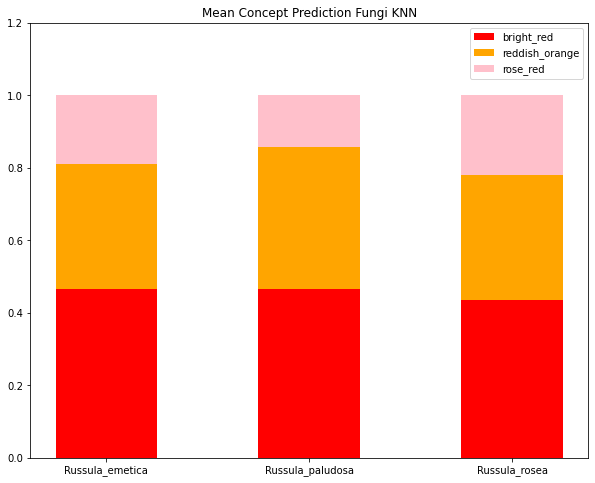

In [32]:
con_colors = ['red', 'orange', 'pink']
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=0.5, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.2)
plt.legend(loc='upper right')
plt.title('Mean Concept Prediction Fungi KNN')
plt.show()

### Frequency of significant concepts

In [52]:
sig_cls_dict = {}
start_ind = 0
# Dominant concept is shown to users (there may be a tie)
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
for i in range(len(classes)):
    len_cls = np.count_nonzero(y_true_bees == i)
    sig_cls_dict[classes[i]] = np.count_nonzero(knn_probs[start_ind:start_ind+len_cls]==np.tile(np.max(knn_probs[start_ind:start_ind+len_cls], axis=1), (len(concepts),1)).T,
                                                axis=0) / len_cls
    start_ind += len_cls
sig_cls_dict

{'Russula_emetica': array([0.76056338, 0.38732394, 0.03521127]),
 'Russula_paludosa': array([0.74910394, 0.36917563, 0.02508961]),
 'Russula_rosea': array([0.76706827, 0.26506024, 0.10843373])}

In [53]:
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'bright_red': array([0.76056338, 0.74910394, 0.76706827]),
 'reddish_orange': array([0.38732394, 0.36917563, 0.26506024]),
 'rose_red': array([0.03521127, 0.02508961, 0.10843373])}

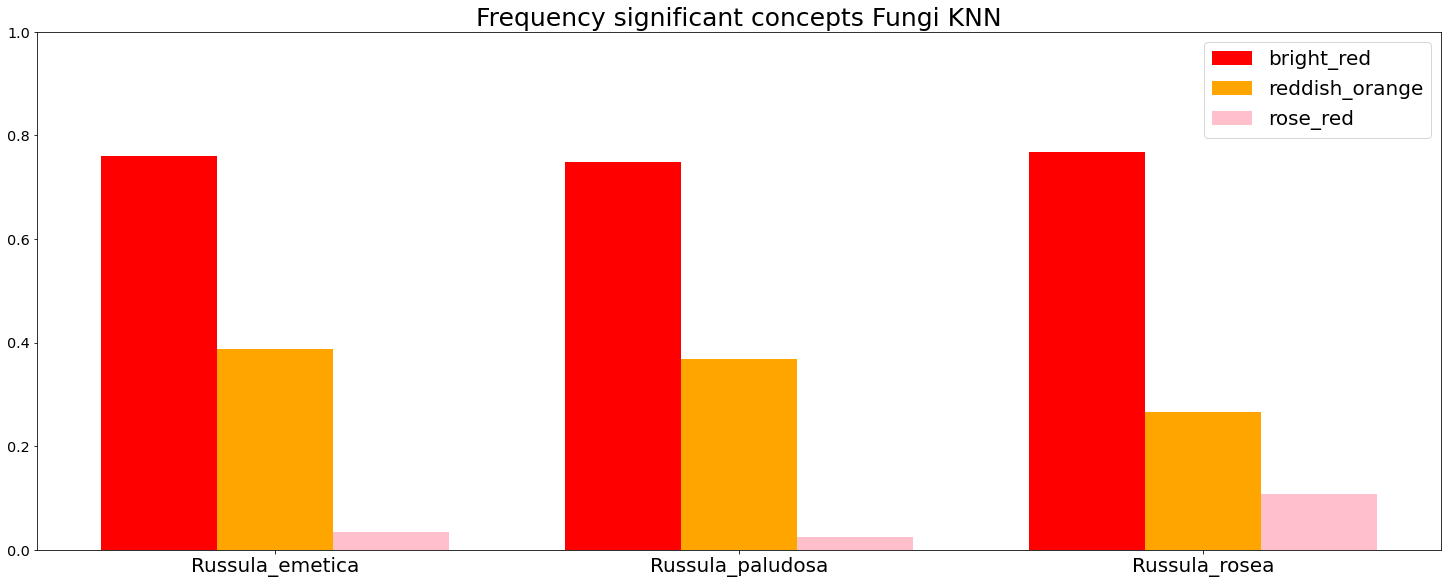

In [54]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
con_colors = ['red', 'orange', 'pink']

fig, ax = plt.subplots(figsize=(20, 8), layout='constrained')
for i, (con, freq) in enumerate(sig_con_dict.items()):
    offset = width * multiplier
    rects = ax.bar(x + offset, freq, width, label=con, color=con_colors[i])
    multiplier += 1

ax.set_title('Frequency significant concepts Fungi KNN', fontsize=25)
ax.set_xticks(x + width, classes, fontsize=20)
ax.yaxis.set_tick_params(labelsize='x-large')
ax.legend(loc='upper right', fontsize=20)
plt.ylim(0.0, 1.0)
plt.show()

### Samples for HIL-Experiment

Russula_paludosa/2351007404-116814.JPG was classified as Russula_emetica.
Expected concepts: 
[0. 1. 0.]
Predicted concepts: 
[0.5 0.4 0.1]
Index: 189


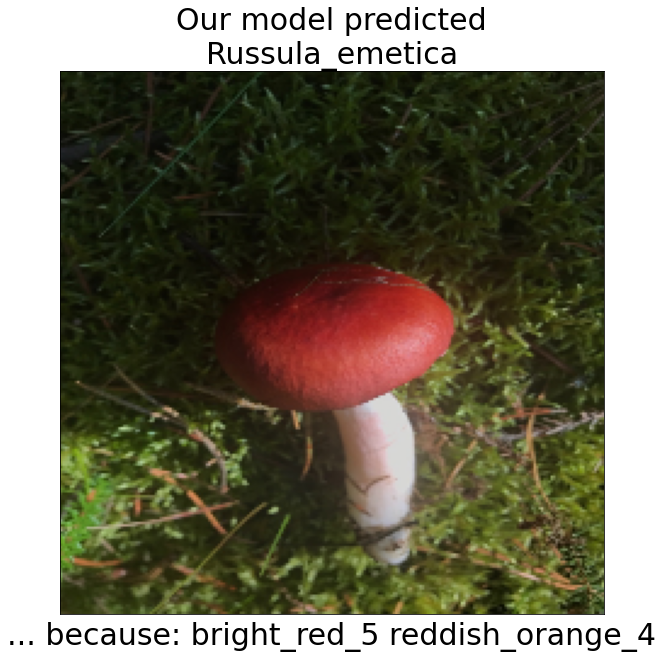

2023-11-07 15:28:00.241698: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


In [44]:
natural_exps = ['bright_red', 'reddish_orange', 'rose_red']
ind_species = [1, 143, 422]
searched_label = 1
count_in_spec_folder = ind_species[searched_label]
# Cannot retrieve file ID from image -> use counter instead and search in species folder
# Note: the dataset is not shuffled.
num_matches, max_match = 0, 5
save_imgs = True
for img, lab in train_val_set.unbatch():
    lab = lab.numpy()
    # Pick true species
    if lab == searched_label:
        # Predict species
        pred_spec = np.argmax( model.predict(tf.expand_dims(img, axis=0)), axis=-1 )[0]
        # Should the sample be a correctly classified one?
        if pred_spec != lab:
            # True concept(s)
            true_con = lookup_cls_concepts[lab]
            # Predict concept(s)
            test_activation = cnn.resnet.predict(tf.expand_dims(img, axis=0))

            pred_con = np.zeros(len(concepts))
            knn_probs = neigh.predict_proba(test_activation)[0]
            for i in range(len(knn_probs)):
                if knn_probs[i] >= thresh:
                    pred_con += concept_basis[i]

            # Should the sample be a correctly explained one?
            if not np.array_equal(true_con, pred_con):
                num_matches += 1
                if num_matches > max_match:
                    file_name = img_dict[str(count_in_spec_folder)]
                    img = tf.io.read_file(FUNGI_PATH + file_name)
                    img = tf.io.decode_jpeg(img, channels = 3)
                    img = tf.image.resize(img, [img_width, img_height])/255.

                    print(file_name + ' was classified as ' + classes[pred_spec] + '.')
                    print('Expected concepts: ')
                    print(true_con)
                    print('Predicted concepts: ')
                    print(knn_probs)
                    print('Index: ' + str(count_in_spec_folder))

                    fig = plt.figure(figsize=(15, 10))
                    plt.imshow(img)
                    plt.xticks([]); plt.yticks([])
                    plt.title('Our model predicted\n' + classes[pred_spec], fontsize = 30)
                    exp_text = '... because:'
                    for i in np.where(pred_con)[0]:
                        exp_text += (' ' + natural_exps[i] + '_' + str(int(knn_probs[i]*10))) # also save the num. of neighbors
                    plt.xlabel(exp_text, fontsize = 30)

                    if save_imgs:
                        fig.savefig('./beexplainable/toloka/fungi/' + file_name[len(classes[lab])+1 : -4] + '_clsno_conno.jpg', bbox_inches = 'tight')
                        shutil.copy(FUNGI_PATH + file_name, './beexplainable/toloka/fungi/')
                    plt.show()
                    break
        count_in_spec_folder += 1